# 07_eval / qualitative_analysis.ipynb

**Purpose:** Pull out **interpretable example pairs** for the paper:
- True positives (correctly flagged OOC) with high gate weight on the explanatory stream.
- False positives (genuine pairs misclassified as OOC).
- False negatives (OOC missed by the model).
- True negatives.

For each, save a small montage with the image, caption, true label, predicted prob, and the gate weights (which stream voted strongest).

**Inputs:**
- `cache/fusion/fusion_predictions.csv` (must contain per-row gate weights `gate_a`, `gate_b`, `gate_c` if available)
- `data/processed/ooc_pairs/manifests/all.csv` — for caption text + image path

**Outputs:**
- `paper/tables/qualitative_examples.csv` — top-K examples per category with metadata
- `paper/figures/qualitative_TP.png`, `qualitative_FP.png`, `qualitative_FN.png`, `qualitative_TN.png` — image grids

**Notes:**
- Only NewsCLIPpings has limited local images, but VERITE & MMFakeBench do — examples are drawn preferentially from datasets with available local images.
- If gate columns are absent we fall back to ranking by predicted probability.


In [1]:
# Imports
from __future__ import annotations
import json, sys, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

warnings.filterwarnings("ignore")
plt.rcParams["figure.dpi"] = 110

NB_DIR = Path.cwd()
ROOT = NB_DIR
for parent in [NB_DIR] + list(NB_DIR.parents):
    if (parent / "src" / "utils" / "paths.py").exists():
        ROOT = parent
        break
sys.path.insert(0, str(ROOT))

from src.utils.paths import (
    ALL_MANIFEST, FUSION_CACHE, PROCESSED_IMAGES, VERITE_IMAGES,
    PAPER, FIGURES, TABLES,
)

# Schema
PROB_COL = "score"
LABEL_COL = "label"
MODEL_COL = "model"
EVAL_SPLIT_COL = "eval_split"
GATE_COLS = ("gate_a", "gate_b", "gate_c")

TABLES.mkdir(parents=True, exist_ok=True)
FIGURES.mkdir(parents=True, exist_ok=True)
print("Repo root:", ROOT)

Repo root: e:\eve-rag


## 1. Load predictions + manifest, merge

In [2]:
fusion_path = FUSION_CACHE / "fusion_predictions.csv"
thresh_path = FUSION_CACHE / "fusion_thresholds.json"
manifest = pd.read_csv(ALL_MANIFEST)
preds = pd.read_csv(fusion_path)

print("preds cols   :", list(preds.columns))
print("manifest cols:", list(manifest.columns)[:25])
print("preds shape:", preds.shape, "| manifest shape:", manifest.shape)

thresholds = json.loads(thresh_path.read_text()) if thresh_path.exists() else {}

# Restrict to GSAF_default for qualitative samples (the deployed model)
preds = preds[preds[MODEL_COL] == "GSAF_default"].copy()
print("After model filter:", preds.shape)

# Gate columns
ga_col, gb_col, gc_col = GATE_COLS
have_gates = all(c in preds.columns for c in GATE_COLS)
print("Have gates:", have_gates)

# Merge with manifest for caption + image_path (manifest already has dataset/split/label too;
# avoid duplicate columns by selecting non-overlapping fields)
mani_keep_cols = [c for c in ["pair_id", "caption", "image_path"] if c in manifest.columns]
merged = preds.merge(manifest[mani_keep_cols].drop_duplicates("pair_id"),
                     on="pair_id", how="left")
print("merged shape:", merged.shape)
merged.head()

preds cols   : ['pair_id', 'dataset', 'split', 'label', 'has_image', 'score', 'gate_a', 'gate_b', 'gate_c', 'eval_split', 'model']
manifest cols: ['pair_id', 'dataset', 'split', 'image_id', 'image_path', 'raw_image_path', 'has_image', 'caption', 'label', 'label_name', 'source_image_id', 'source_text_id', 'original_id', 'clip_image_key', 'clip_text_key', 'text_source', 'image_source', 'fake_cls', 'topic', 'source', 'timestamp', 'title', 'raw_label', 'notes']
preds shape: (128945, 11) | manifest shape: (97361, 24)
After model filter: (25789, 11)
Have gates: True
merged shape: (25789, 13)


,pair_id,dataset,split,label,has_image,score,gate_a,gate_b,gate_c,eval_split,model,caption,image_path
0,nc_92318_0,newsclippings,val,0,0,0.506079,0.098520,0.710244,0.191237,newsclippings_val,GSAF_default,People walk in the parking lot of an Ikea stor...,NaN
1,nc_92318_1,newsclippings,val,1,0,0.859827,0.186465,0.388351,0.425184,newsclippings_val,GSAF_default,An an armed suspect shot an armored car guard ...,NaN
2,nc_224103_0,newsclippings,val,0,0,0.418595,0.177939,0.647382,0.174678,newsclippings_val,GSAF_default,The Olympics are over but the Paralympics begi...,NaN
3,nc_224103_1,newsclippings,val,1,0,0.872252,0.234153,0.401523,0.364325,newsclippings_val,GSAF_default,Thursday 26 April The New York Rangers celebra...,NaN
4,nc_367276_0,newsclippings,val,0,0,0.362906,0.017784,0.774253,0.207963,newsclippings_val,GSAF_default,The Brandenburg Gate stands illuminated during...,NaN


## 2. Pick threshold per dataset and tag confusion-matrix bucket

In [3]:
# Threshold per row, using eval_split key
def thresh_for_row(r):
    key = r[EVAL_SPLIT_COL]
    if pd.isna(key):
        return float(thresholds.get("default", 0.5))
    return float(thresholds.get(key, thresholds.get("default", 0.5)))

merged["_threshold"] = merged.apply(thresh_for_row, axis=1)
merged["_y_pred"] = (merged[PROB_COL].astype(float) >= merged["_threshold"]).astype(int)
merged["_y_true"] = merged[LABEL_COL].astype(int)

def bucket(r):
    yt, yp = r["_y_true"], r["_y_pred"]
    if yt == 1 and yp == 1: return "TP"
    if yt == 0 and yp == 1: return "FP"
    if yt == 1 and yp == 0: return "FN"
    return "TN"

merged["_bucket"] = merged.apply(bucket, axis=1)
print("Bucket distribution:")
print(merged["_bucket"].value_counts())
print()
print("Per (dataset, split):")
print(merged.groupby(["dataset", "split", "_bucket"]).size().head(40))

Bucket distribution:
_bucket
TP    11373
TN     7338
FN     3784
FP     3294
Name: count, dtype: int64

Per (dataset, split):
dataset        split  _bucket
mmfakebench    test   FN         1177
                      FP          995
                      TN         2005
                      TP         5823
               val    FN           53
                      FP           37
                      TN          113
                      TP          297
newsclippings  test   FN         1335
                      FP          940
                      TN         2692
                      TP         2297
               val    FN         1159
                      FP         1008
                      TN         2504
                      TP         2353
verite         test   FN           60
                      FP          314
                      TN           24
                      TP          603
dtype: int64


## 3. Resolve image paths

In [4]:
def resolve_image(row):
    """Return absolute Path to image if it exists locally, else None."""
    cand = row.get("image_path")
    if pd.isna(cand) or not cand:
        return None
    p = Path(str(cand))
    if p.is_absolute() and p.exists():
        return p
    # try processed-images flat folder
    for base in [PROCESSED_IMAGES, VERITE_IMAGES, ROOT / "data" / "raw" / "mmfakebench"]:
        cand2 = base / p.name
        if cand2.exists():
            return cand2
    # try as-given relative to ROOT
    cand3 = ROOT / p
    if cand3.exists():
        return cand3
    return None

merged["_image_path"] = merged.apply(resolve_image, axis=1)
print("Rows with local image:", merged["_image_path"].notna().sum(), "/", len(merged))
print("By dataset:")
print(merged.groupby("dataset")["_image_path"].apply(lambda s: s.notna().sum()))

Rows with local image: 11121 / 25789
By dataset:
dataset
mmfakebench      10500
newsclippings        0
verite             621
Name: _image_path, dtype: int64


## 4. Pick top-K examples per bucket (prefer with local image, prefer high-confidence)

In [5]:
K = 6
TARGET_DATASETS = ["mmfakebench", "verite", "newsclippings"]
TEST_SPLITS = ["mmfakebench_test", "verite_test", "newsclippings_test"]

def score_example(row, bk):
    p = float(row[PROB_COL])
    if bk == "TP": return p
    if bk == "TN": return 1.0 - p
    if bk == "FP": return p
    if bk == "FN": return 1.0 - p
    return 0.0

selected = []
for bk in ["TP", "FP", "FN", "TN"]:
    cand = merged[(merged["_bucket"] == bk) & (merged[EVAL_SPLIT_COL].isin(TEST_SPLITS))].copy()
    cand = cand[cand["dataset"].isin(TARGET_DATASETS)]
    cand["_pref"] = cand["_image_path"].notna().astype(int)
    cand["_score"] = cand.apply(lambda r: score_example(r, bk), axis=1)
    cand = cand.sort_values(["_pref", "_score"], ascending=[False, False]).head(K)
    cand["_bucket"] = bk
    selected.append(cand)

selected_df = pd.concat(selected, ignore_index=True)

caption_col = "caption" if "caption" in selected_df.columns else None
keep_cols = ["_bucket", "pair_id", "dataset", "split", "_y_true", "_y_pred",
             PROB_COL, "_threshold"]
if caption_col: keep_cols.append(caption_col)
if have_gates: keep_cols += list(GATE_COLS)
keep_cols.append("_image_path")

selected_df[keep_cols].to_csv(TABLES / "qualitative_examples.csv", index=False)
print("Saved:", TABLES / "qualitative_examples.csv")
selected_df[keep_cols].head(24)

Saved: E:\eve-rag\paper\tables\qualitative_examples.csv


,_bucket,pair_id,dataset,split,_y_true,_y_pred,score,_threshold,caption,gate_a,gate_b,gate_c,_image_path
0,TP,mmfakebench_test_05671,mmfakebench,test,1,1,0.988710,0.5,Mars Rover Uncovers Ancient Martian Civilizati...,0.678102,0.047874,0.274024,E:\eve-rag\data\processed\ooc_pairs\images\mmf...
1,TP,mmfakebench_test_05903,mmfakebench,test,1,1,0.988251,0.5,"Zoe Saldana Transforms Career Horizons, Embrac...",0.690102,0.040096,0.269802,E:\eve-rag\data\processed\ooc_pairs\images\mmf...
2,TP,mmfakebench_test_05648,mmfakebench,test,1,1,0.987748,0.5,Quantum Physicists Uncover Secret to Teleporta...,0.701476,0.041604,0.256921,E:\eve-rag\data\processed\ooc_pairs\images\mmf...
3,TP,mmfakebench_test_05750,mmfakebench,test,1,1,0.987399,0.5,"Chris Paul Empowers NBA Franchise Ownership, S...",0.704618,0.041763,0.253619,E:\eve-rag\data\processed\ooc_pairs\images\mmf...
4,TP,mmfakebench_test_05922,mmfakebench,test,1,1,0.987358,0.5,Enigmatic Elegance: Shannon Lee Unveiled as a ...,0.708120,0.040107,0.251773,E:\eve-rag\data\processed\ooc_pairs\images\mmf...
5,TP,mmfakebench_test_05268,mmfakebench,test,1,1,0.987163,0.5,Pentagon Initiates Top-Secret Alien Partnershi...,0.690756,0.048088,0.261156,E:\eve-rag\data\processed\ooc_pairs\images\mmf...
6,FP,mmfakebench_test_00426,mmfakebench,test,0,1,0.929970,0.5,The US warship is currently on a fiveday visit...,0.247928,0.386630,0.365442,E:\eve-rag\data\processed\ooc_pairs\images\mmf...
7,FP,verite_0267,verite,test,0,1,0.915828,0.5,A photograph shows a woman recruit of the Soma...,0.030153,0.457290,0.512556,E:\eve-rag\data\processed\ooc_pairs\images\ver...
8,FP,verite_0582,verite,test,0,1,0.909111,0.5,A photograph shows Red Cross nurses arriving o...,0.022262,0.499546,0.478192,E:\eve-rag\data\processed\ooc_pairs\images\ver...
9,FP,verite_0168,verite,test,0,1,0.908838,0.5,Image shows a member of the 173rd Airborne Bri...,0.023430,0.504273,0.472297,E:\eve-rag\data\processed\ooc_pairs\images\ver...


## 5. Render image grids (one figure per bucket)

Saved: E:\eve-rag\paper\figures\qualitative_TP.png


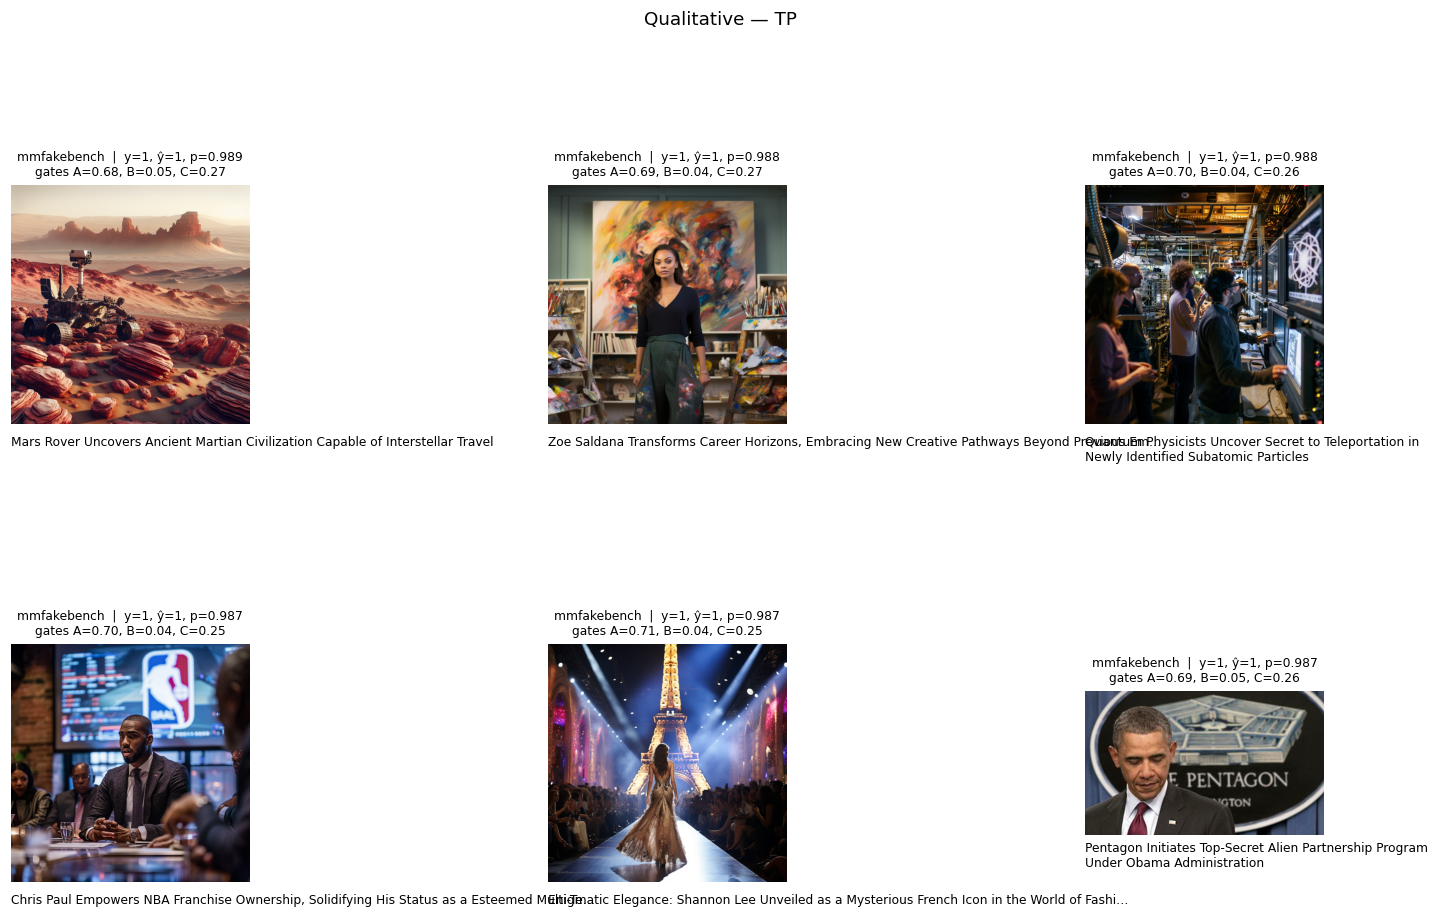

Saved: E:\eve-rag\paper\figures\qualitative_FP.png


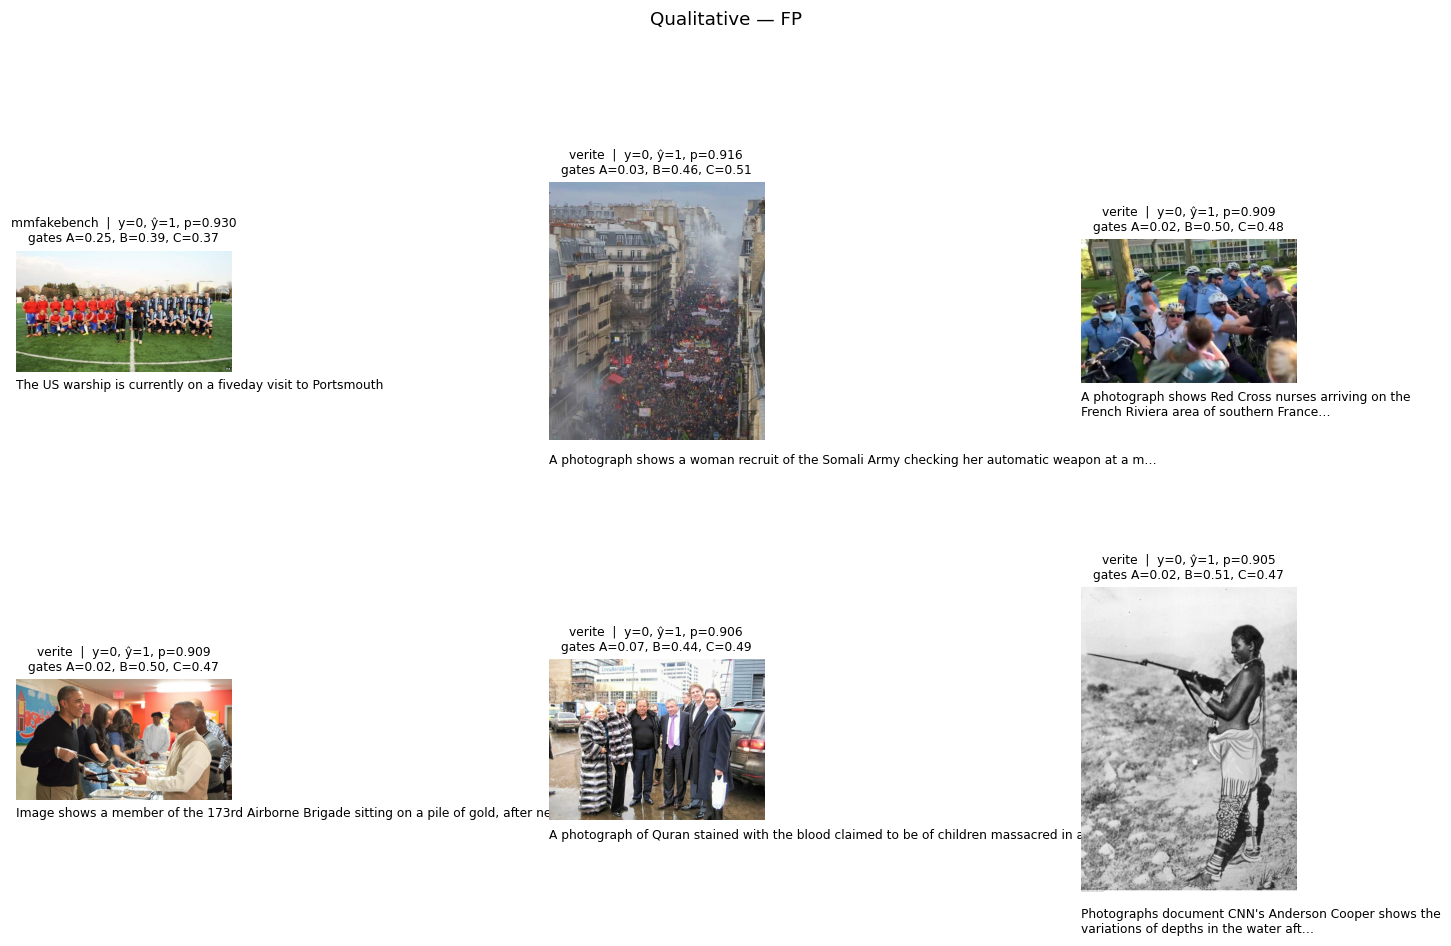

Saved: E:\eve-rag\paper\figures\qualitative_FN.png


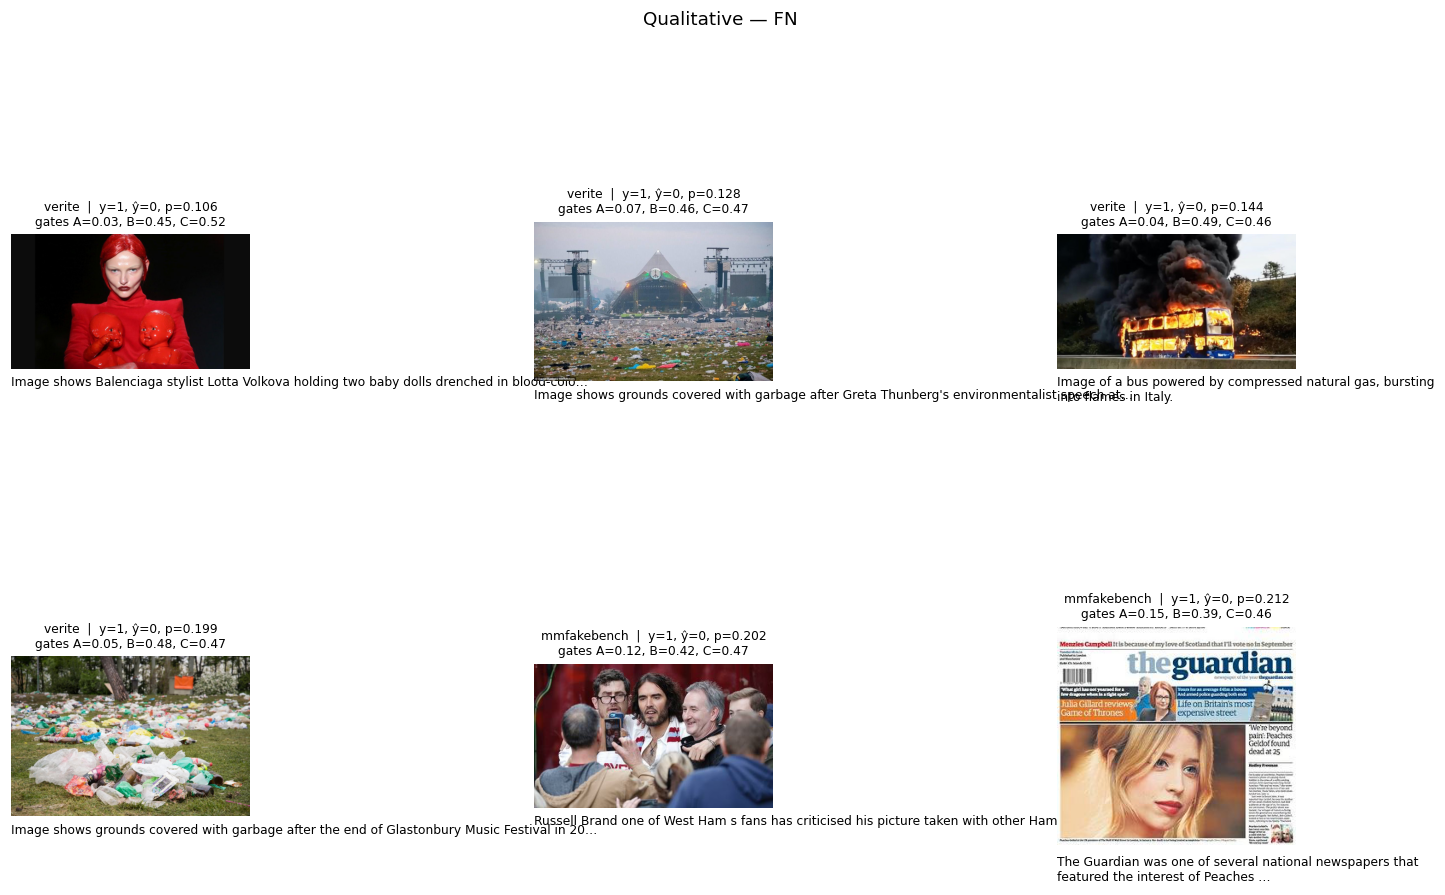

Saved: E:\eve-rag\paper\figures\qualitative_TN.png


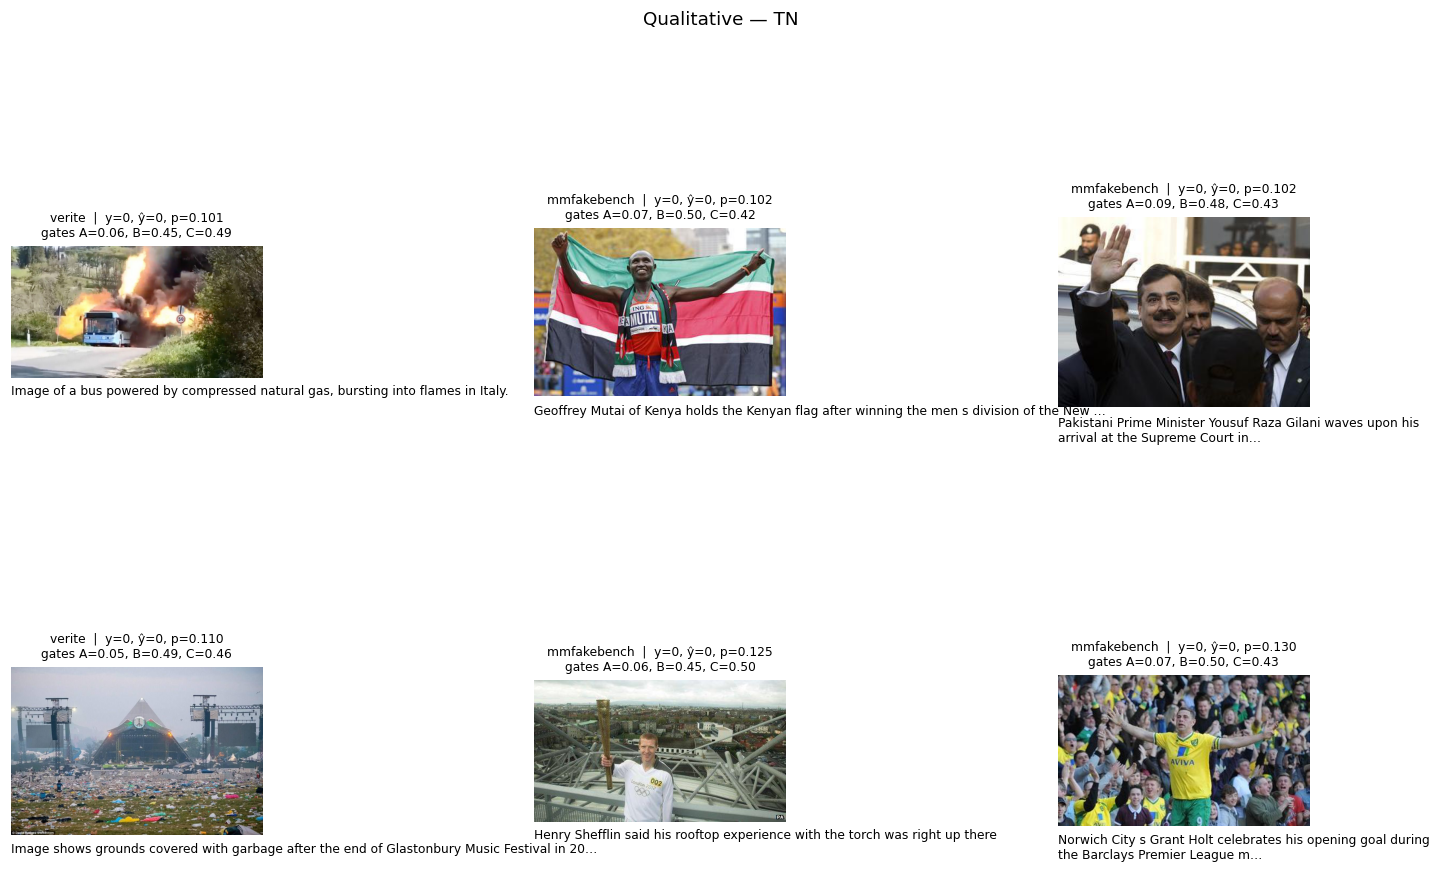

In [6]:
def render_bucket(bucket_name):
    sub = selected_df[selected_df["_bucket"] == bucket_name].reset_index(drop=True)
    if sub.empty:
        print(f"No {bucket_name} rows.")
        return
    n = len(sub)
    cols = 3
    rows = int(np.ceil(n / cols))
    fig, axes = plt.subplots(rows, cols, figsize=(cols * 4.4, rows * 4.4))
    axes = np.atleast_2d(axes)
    for k in range(rows * cols):
        ax = axes[k // cols, k % cols]
        ax.axis("off")
        if k >= n:
            continue
        r = sub.iloc[k]
        img_path = r["_image_path"]
        if pd.notna(img_path) and Path(img_path).exists():
            try:
                img = Image.open(img_path).convert("RGB")
                ax.imshow(img)
            except Exception as e:
                ax.text(0.5, 0.5, f"[load err]\n{e}", ha="center", va="center", fontsize=8)
        else:
            ax.text(0.5, 0.5, "[no local image]", ha="center", va="center", fontsize=10, color="gray")

        cap = r.get(caption_col) if caption_col else ""
        if isinstance(cap, str) and len(cap) > 90:
            cap = cap[:90] + "…"
        meta = f"{r['dataset']}  |  y={int(r['_y_true'])}, ŷ={int(r['_y_pred'])}, p={float(r[PROB_COL]):.3f}"
        if have_gates:
            meta += f"\ngates A={float(r[GATE_COLS[0]]):.2f}, B={float(r[GATE_COLS[1]]):.2f}, C={float(r[GATE_COLS[2]]):.2f}"
        ax.set_title(meta, fontsize=8)
        ax.text(0.0, -0.05, str(cap) if cap is not None else "", transform=ax.transAxes,
                fontsize=8, va="top", wrap=True)
    fig.suptitle(f"Qualitative — {bucket_name}", fontsize=12, y=1.02)
    plt.tight_layout()
    out = FIGURES / f"qualitative_{bucket_name}.png"
    plt.savefig(out, bbox_inches="tight", dpi=140)
    print("Saved:", out)
    plt.show()

for bk in ["TP", "FP", "FN", "TN"]:
    render_bucket(bk)

## 6. Stream-attribution summary (which stream the gate trusts most)

In [7]:
# Stream-attribution summary
if have_gates:
    test_only = merged[merged[EVAL_SPLIT_COL].isin(TEST_SPLITS)].copy()
    gate_long = pd.melt(
        test_only,
        id_vars=["dataset", "_bucket"],
        value_vars=list(GATE_COLS),
        var_name="stream",
        value_name="gate_weight",
    )
    gate_long["stream"] = gate_long["stream"].map({GATE_COLS[0]: "A", GATE_COLS[1]: "B", GATE_COLS[2]: "C"})
    summary = gate_long.groupby(["dataset", "_bucket", "stream"])["gate_weight"].mean().unstack("stream")
    print(summary.round(3))
    summary.to_csv(TABLES / "qualitative_gate_attribution.csv", float_format="%.4f")
    print("Saved:", TABLES / "qualitative_gate_attribution.csv")
else:
    print("Gate columns not found — skipping attribution summary.")

stream                     A      B      C
dataset       _bucket                     
mmfakebench   FN       0.367  0.382  0.251
              FP       0.208  0.295  0.497
              TN       0.172  0.399  0.430
              TP       0.465  0.178  0.358
newsclippings FN       0.197  0.565  0.238
              FP       0.201  0.501  0.297
              TN       0.171  0.611  0.218
              TP       0.199  0.479  0.322
verite        FN       0.061  0.491  0.448
              FP       0.035  0.506  0.458
              TN       0.059  0.476  0.464
              TP       0.035  0.508  0.457
Saved: E:\eve-rag\paper\tables\qualitative_gate_attribution.csv


---
**Done.** Use these figures and the CSV in the paper's qualitative section. Cherry-pick the most pedagogical examples (clear OOC mismatches; illustrative failures).